In [2]:
import ROOT
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# load library from the Mach3 build
ROOT.gSystem.AddDynamicPath("../build/")
ROOT.gSystem.Load("libduneanaobj_StandardRecord")

Welcome to JupyROOT 6.28/12


0

In [3]:
# open CAF .root, and get event tree
f = ROOT.TFile("/storage/1/st15719/dune/atmo/Mach3_Inputs/CAFs/caf_new_sum.2.6M_weighted.root")
caf_tree = f.Get("cafTree")

Warning in <TClass::Init>: no dictionary for class genie::NtpMCEventRecord is available
Warning in <TClass::Init>: no dictionary for class genie::NtpMCRecordI is available
Warning in <TClass::Init>: no dictionary for class genie::NtpMCRecHeader is available
Warning in <TClass::Init>: no dictionary for class genie::EventRecord is available
Warning in <TClass::Init>: no dictionary for class genie::GHepRecord is available
Warning in <TClass::Init>: no dictionary for class genie::Interaction is available
Warning in <TClass::Init>: no dictionary for class genie::InitialState is available
Warning in <TClass::Init>: no dictionary for class genie::Target is available
Warning in <TClass::Init>: no dictionary for class genie::ProcessInfo is available
Warning in <TClass::Init>: no dictionary for class genie::Kinematics is available
Warning in <TClass::Init>: no dictionary for class pair<genie::EKineVar,double> is available
Warning in <TClass::Init>: no dictionary for class genie::XclsTag is avail

In [4]:
var_labels = ["true_pdg", "true_energy", "true_n_prim_mu", "reco_ok", "reco_n_prim", "reco_energy_lep_calo", "reco_energy_e_calo", "reco_energy_calo",'is_charged_current','x_momentum','y_momentum','z_momentum','x_vertex','y_vertex','z_vertex',"muon_range_algorithm","muon_mcs_algorithm","longest_track_x","longest_track_y","longest_track_z","highest_energy_shower_x","highest_energy_shower_y","highest_energy_shower_z","CVN_score_electron_like","CVN_score_muon_like","CVN_score_neutral_current_like"]
data_arrays=[]

n_processed_events=0
for entry in caf_tree:

    data_array = {key: None for key in var_labels}

    # get truth information
    n_true_nu = entry.rec.mc.nu.size()

    if n_true_nu != 1:
        print(f"ERROR: unexpected mc truth size: {n_true_nu}; should be 1")
        break
    true_nu = entry.rec.mc.nu[0]
    
    data_array["true_energy"] = true_nu.E

    # true nu species
    data_array["true_pdg"] = true_nu.pdg

    #adding charged current information into the dataframe
    data_array["is_charged_current"] = bool(true_nu.iscc)

    #adding momentum information into the dataframe
    data_array["x_momentum"] = float(true_nu.momentum.x)
    data_array["y_momentum"] = float(true_nu.momentum.y)
    data_array["z_momentum"] = float(true_nu.momentum.z)
    
    #adding vertex information into the dataframe
    data_array["x_vertex"] = true_nu.vtx.x
    data_array["y_vertex"] = true_nu.vtx.y
    data_array["z_vertex"] = true_nu.vtx.z

     # n primary true muons
    true_n_primary_mu=0

    for nu_primary in true_nu.prim:
        primary_pdg = nu_primary.pdg
        if abs(primary_pdg) == 13:
            true_n_primary_mu=true_n_primary_mu+1

    data_array["true_n_prim_mu"] = true_n_primary_mu
    ##

    # get reco information
    reco_ok=False
    reco_n_prim = np.nan
    reco_energy_lep_calo = np.nan
    reco_energy_e_calo = np.nan
    reco_energy_calo = np.nan

    n_reco_nu = entry.rec.common.ixn.pandora.size()

    if n_reco_nu == 0:
        print(f"WARNING: no reco nu!")
    elif n_reco_nu != 1:
        print(f"ERROR: unexpected n of reco nu: {n_reco_nu}")
        break
    else:
        reco_ok=True

    if reco_ok:
        reco_nu = entry.rec.common.ixn.pandora[0]
        reco_n_prim=0
        reco_energy_lep_calo = reco_nu.Enu.lep_calo
        reco_energy_e_calo = reco_nu.Enu.e_calo
        reco_energy_calo = reco_nu.Enu.calo
        
        for reco_pfp in reco_nu.part.pandora:
            if reco_pfp.primary:
                reco_n_prim=reco_n_prim+1

    data_array["reco_ok"] = reco_ok
    data_array["reco_n_prim"] = reco_n_prim
    data_array["reco_energy_lep_calo"] = reco_energy_lep_calo
    data_array["reco_energy_e_calo"] = reco_energy_e_calo
    data_array["reco_energy_calo"] = reco_energy_calo

    #adding more algorithm information to the dataframe
    data_array["muon_range_algorithm"] = reco_nu.Enu.mu_range
    data_array["muon_mcs_algorithm"] = reco_nu.Enu.mu_mcs

    #adding longest track information to the dataframe
    data_array["longest_track_x"] = reco_nu.dir.lngtrk.x
    data_array["longest_track_y"] = reco_nu.dir.lngtrk.y
    data_array["longest_track_z"] = reco_nu.dir.lngtrk.z

    #adding highest energy shower information to the dataframe
    data_array["highest_energy_shower_x"] = reco_nu.dir.heshw.x 
    data_array["highest_energy_shower_y"] = reco_nu.dir.heshw.y 
    data_array["highest_energy_shower_z"] = reco_nu.dir.heshw.z 

    #adding CVN scores to the dataframe
    data_array["CVN_score_electron_like"] = reco_nu.nuhyp.cvn.nue 
    data_array["CVN_score_muon_like"] = reco_nu.nuhyp.cvn.numu
    data_array["CVN_score_neutral_current_like"] = reco_nu.nuhyp.cvn.nc

    data_arrays.append(list(data_array.values()))
    ###

    n_processed_events=n_processed_events+1

print(f"Processed {n_processed_events} events")

Processed 2884703 events


Warning in <TStreamerInfo::BuildOld>: Cannot convert caf::SRSAND::ixn from type: vector<caf::SRGArInt> to type: vector<caf::SRSANDInt>, skip element
Error in <TBranchElement::SetAddress>: For nd.sand.ixn, we can not convert vector<caf::SRGArInt> into vector<caf::SRSANDInt>



In [5]:
df = pd.DataFrame(data_arrays, columns=var_labels)
print(df)

         true_pdg  true_energy  true_n_prim_mu  reco_ok  reco_n_prim  \
0             -12    35.698929               0     True          9.0   
1             -12     0.425595               0     True          1.0   
2             -14     1.668767               1     True          3.0   
3              16     3.011142               0    False          NaN   
4              14     0.633065               1     True          2.0   
...           ...          ...             ...      ...          ...   
2884698        14     1.042722               0     True          1.0   
2884699        14     0.311960               1     True          1.0   
2884700        14     0.278793               1     True          2.0   
2884701        12     7.232777               0     True          2.0   
2884702       -14     0.202625               0     True          1.0   

         reco_energy_lep_calo  reco_energy_e_calo  reco_energy_calo  \
0                   28.529816           28.432413         32.386

         true_pdg  true_energy  true_n_prim_mu  reco_ok  reco_n_prim  \
0             -12    35.698929               0     True          9.0   
1             -12     0.425595               0     True          1.0   
2             -14     1.668767               1     True          3.0   
4              14     0.633065               1     True          2.0   
5              16     1.200049               0     True          1.0   
...           ...          ...             ...      ...          ...   
2884698        14     1.042722               0     True          1.0   
2884699        14     0.311960               1     True          1.0   
2884700        14     0.278793               1     True          2.0   
2884701        12     7.232777               0     True          2.0   
2884702       -14     0.202625               0     True          1.0   

         reco_energy_lep_calo  reco_energy_e_calo  reco_energy_calo  \
0                   28.529816           28.432413         32.386

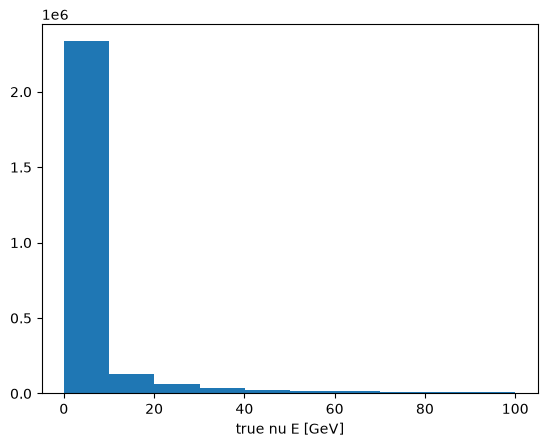

In [6]:
# filter out events with no reco info
df_reco_ok=df[df["reco_ok"] == True]
print(df_reco_ok)

# column to array
true_nu_e = df_reco_ok['true_energy'].to_numpy()
print(true_nu_e)

# make plot
plt.hist(true_nu_e) 
plt.xlabel("true nu E [GeV]") 
plt.show()

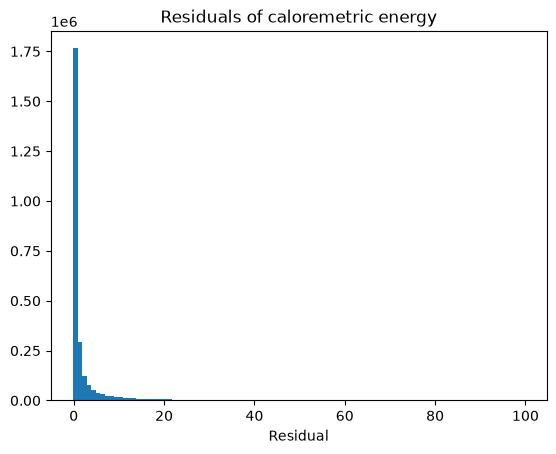

In [7]:
var_labels = ["true_pdg", "true_energy", "true_n_prim_mu", "reco_ok", "reco_n_prim", "reco_energy_lep_calo", "reco_energy_e_calo", "reco_energy_calo"]
def residuals(true,reco):
    """Takes an array of true data and an array of reconstructed data and returns an array of the residuals"""
    residual = true-reco
    return residual

def fractional_residuals(true,reco):
    """Takes an array of true data and an array of reconstructed data and returns an array of the fractional residuals"""
    fractional_residual = (true-reco)*true
    return fractional_residual

def plot_hist(data,title,axis_label,x_scale,y_scale,bin_num):
    """Takes an array of data, a string of the plot and x axis titles, number of bins, and information on the axis scales and plots a histogram"""
    if x_scale == "":
        x_scale = 'linear'
    if y_scale == "":
        y_scale = 'linear'

    bin_specification = bin_num
    if x_scale == 'log':
        bin_specification = np.logspace(np.log10(np.min(data)),np.log10(np.max(data)), bin_num)
    
    plt.hist(data,bins=bin_specification)
    plt.xlabel(axis_label)
    plt.title(title)
    plt.xscale(x_scale)
    plt.yscale(y_scale)
    plt.show()


residual_energy_lep_calo = residuals(df_reco_ok["true_energy"],df_reco_ok["reco_energy_lep_calo"])
residual_energy_e_calo = residuals(df_reco_ok["true_energy"],df_reco_ok["reco_energy_e_calo"])
residual_energy_calo = residuals(df_reco_ok["true_energy"],df_reco_ok["reco_energy_calo"])

fractional_residual_energy_lep_calo = fractional_residuals(df_reco_ok["true_energy"],df_reco_ok["reco_energy_lep_calo"])
fractional_residual_energy_e_calo = fractional_residuals(df_reco_ok["true_energy"],df_reco_ok["reco_energy_e_calo"])
fractional_residual_energy_calo = fractional_residuals(df_reco_ok["true_energy"],df_reco_ok["reco_energy_calo"])

plot_hist(residual_energy_calo,'Residuals of caloremetric energy','Residual','','',100)

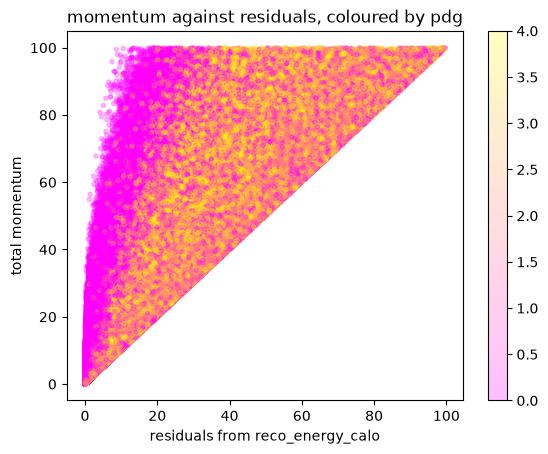

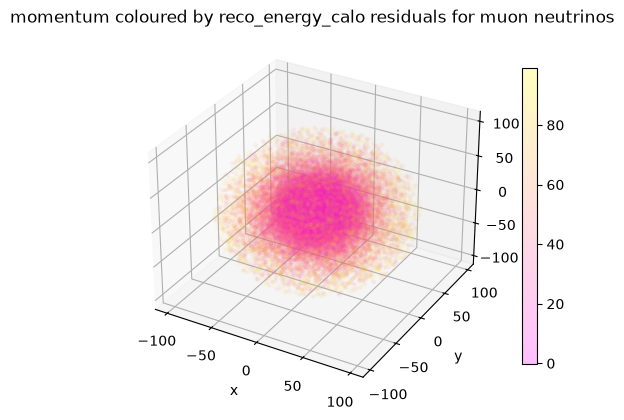

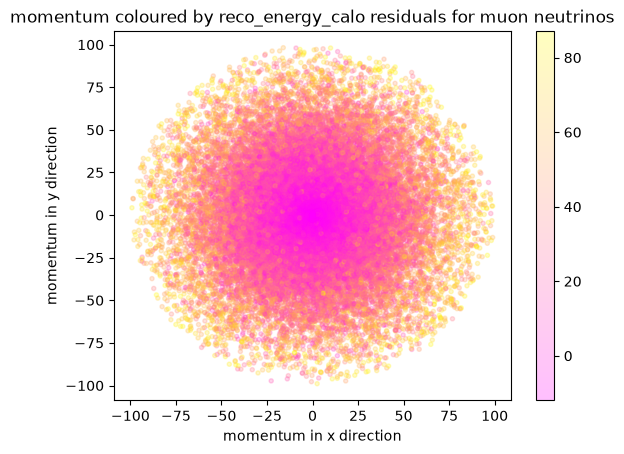

In [ ]:
def plot_scatter(x_data,y_data,colours,x_name,y_name,title):
    """
    Takes two arrays of data, a colourmap, labels of the data and plots a scatter graph
    """

    colours_norm = np.abs(colours)-12*np.ones((colours.shape))

    plt.scatter(x_data,y_data,c=colours_norm, marker='.',cmap='spring',alpha=0.25)
    plt.xlabel(x_name)
    plt.ylabel(y_name)
    plt.title(title)  
    plt.colorbar()
    plt.show()

def momentum_3d_plot(x,y,z,colours,x_name,y_name,z_name,title):
    """
    Takes three inputs and their names and plots a 3d scatter plot
    """
    fig = plt.figure()
    ax = fig.add_subplot(projection='3d')
    scatter=ax.scatter(x, y, z,c=colours ,marker='.',cmap='spring',alpha = 0.25)
    plt.colorbar(scatter, ax=ax, shrink=0.8)
    ax.set_xlabel(x_name)
    ax.set_ylabel(y_name)
    ax.set_zlabel(z_name)
    ax.set_title(title)
    plt.show()

def plot_double_scatter(x_data_1,y_data_1,x_data_2,y_data_2,colour1,colour2,x_name,y_name,label_1,label_2,title):
    """
    Takes 4 arrays of data, a colourmap, labels of the data and plots a scatter graph
    """

    plt.scatter(x_data_1,y_data_1,c=colour1, marker='.',cmap='spring',alpha=0.25,label=label_1)
    plt.scatter(x_data_2,y_data_2,c=colour2, marker='.',cmap='cool',alpha=0.25,label=label_2)
    plt.xlabel(x_name)
    plt.ylabel(y_name)
    plt.title(title)  
    plt.legend()
    plt.colorbar()
    plt.colorbar()
    plt.show()

def momentum_3d_double_plot(x1,y1,z1,x2,y2,z2,colours1,colours2,x_name,y_name,z_name,label_1,label_2,title):
    """
    Takes 6 inputs and their names and plots a 3d scatter plot
    """
    fig = plt.figure()
    ax = fig.add_subplot(projection='3d')
    scatter1=ax.scatter(x1, y1, z1,c=colours1 ,marker='.',cmap='spring',alpha = 0.2,label=label_1)
    scatter2=ax.scatter(x2, y2, z2,c=colours2 ,marker='.',cmap='cool',alpha = 0.2,label=label_2)
    plt.colorbar(scatter1, ax=ax, shrink=0.8)
    plt.colorbar(scatter2, ax=ax, shrink=0.8)
    ax.set_xlabel(x_name)
    ax.set_ylabel(y_name)
    ax.set_zlabel(z_name)
    ax.set_title(title)
    plt.show()

#creating an array of muon and electron neutrinos
muon_neutrinos = df_reco_ok[df_reco_ok["true_pdg"]==14]
electron_neutrinos = df_reco_ok[df_reco_ok["true_pdg"]==12]

#calculating residuals for these electron and muon dataframes
muon_residuals_calo = (residuals(muon_neutrinos["true_energy"],muon_neutrinos["reco_energy_calo"]))
electron_residuals_calo = (residuals(electron_neutrinos["true_energy"],electron_neutrinos["reco_energy_calo"]))

muon_residuals_e_calo = (residuals(muon_neutrinos["true_energy"],muon_neutrinos["reco_energy_e_calo"]))
electron_residuals_e_calo = (residuals(electron_neutrinos["true_energy"],electron_neutrinos["reco_energy_e_calo"]))

muon_residuals_lep_calo = (residuals(muon_neutrinos["true_energy"],muon_neutrinos["reco_energy_lep_calo"]))
electron_residuals_lep_calo = (residuals(electron_neutrinos["true_energy"],electron_neutrinos["reco_energy_lep_calo"]))


plot_scatter(residual_energy_calo,(np.sqrt(df_reco_ok['x_momentum']**2+df_reco_ok['y_momentum']**2+df_reco_ok['z_momentum']**2)), np.abs(df_reco_ok['true_pdg']),'residuals from reco_energy_calo', 'total momentum','momentum against residuals, coloured by pdg')

#plotting for muon neutrinos
momentum_3d_plot(muon_neutrinos['x_momentum'],muon_neutrinos['y_momentum'],muon_neutrinos['z_momentum'],muon_residuals_calo,'x','y','z','momentum coloured by reco_energy_calo residuals for muon neutrinos')
plot_scatter(muon_neutrinos['x_momentum'],muon_neutrinos['y_momentum'],muon_residuals_calo,'momentum in x direction', 'momentum in y direction','momentum coloured by reco_energy_calo residuals for muon neutrinos')
plot_scatter(muon_neutrinos['y_momentum'],muon_neutrinos['z_momentum'],muon_residuals_calo,'momentum in y direction', 'momentum in z direction','momentum coloured by reco_energy_calo residuals for muon neutrinos')
plot_scatter(muon_neutrinos['x_momentum'],muon_neutrinos['z_momentum'],muon_residuals_calo,'momentum in x direction', 'momentum in z direction','momentum coloured by reco_energy_calo residuals for muon neutrinos')

#plotting for electron neutrinos
momentum_3d_plot(electron_neutrinos['x_momentum'],electron_neutrinos['y_momentum'],electron_neutrinos['z_momentum'],electron_residuals_calo,'x','y','z','momentum coloured by reco_energy_calo residuals for electron neutrinos')
plot_scatter(electron_neutrinos['x_momentum'],electron_neutrinos['y_momentum'],electron_residuals_calo,'momentum in x direction', 'momentum in y direction','momentum coloured by reco_energy_calo residuals for electron neutrinos')
plot_scatter(electron_neutrinos['y_momentum'],electron_neutrinos['z_momentum'],electron_residuals_calo,'momentum in y direction', 'momentum in z direction','momentum coloured by reco_energy_calo residuals for electron neutrinos')
plot_scatter(electron_neutrinos['x_momentum'],electron_neutrinos['z_momentum'],electron_residuals_calo,'momentum in x direction', 'momentum in z direction','momentum coloured by reco_energy_calo residuals for electron neutrinos')

#plotting the momentum colour coded with residuals from reco_energy_e_calo

#plotting for muon neutrinos
print('muon neutrino, reco energy e calo')
momentum_3d_plot(muon_neutrinos['x_momentum'],muon_neutrinos['y_momentum'],muon_neutrinos['z_momentum'],muon_residuals_e_calo,'x','y','z','momentum coloured by reco_energy_e_calo residuals for muon neutrinos')
plot_scatter(muon_neutrinos['x_momentum'],muon_neutrinos['y_momentum'],muon_residuals_e_calo,'momentum in x direction', 'momentum in y direction','momentum coloured by reco_energy_e_calo residuals for muon neutrinos')
plot_scatter(muon_neutrinos['y_momentum'],muon_neutrinos['z_momentum'],muon_residuals_e_calo,'momentum in y direction', 'momentum in z direction','momentum coloured by reco_energy_e_calo residuals for muon neutrinos')
plot_scatter(muon_neutrinos['x_momentum'],muon_neutrinos['z_momentum'],muon_residuals_e_calo,'momentum in x direction', 'momentum in z direction','momentum coloured by reco_energy_e_calo residuals for muon neutrinos')

#plotting for electron neutrions
print('electron neutrino, reco energy e calo')
momentum_3d_plot(electron_neutrinos['x_momentum'],electron_neutrinos['y_momentum'],electron_neutrinos['z_momentum'],electron_residuals_e_calo,'x','y','z','momentum coloured by reco_energy_e_calo residuals for electron neutrinos')
plot_scatter(electron_neutrinos['x_momentum'],electron_neutrinos['y_momentum'],electron_residuals_e_calo,'momentum in x direction [electron]', 'momentum in y direction','momentum coloured by reco_energy_e_calo residuals for electron neutrinos')
plot_scatter(electron_neutrinos['y_momentum'],electron_neutrinos['z_momentum'],electron_residuals_e_calo,'momentum in y direction [electron]', 'momentum in z direction','momentum coloured by reco_energy_e_calo residuals for electron neutrinos')
plot_scatter(electron_neutrinos['x_momentum'],electron_neutrinos['z_momentum'],electron_residuals_e_calo,'momentum in x direction [electron]', 'momentum in z direction','momentum coloured by reco_energy_e_calo residuals for electron neutrinos')

#plotting the momentum colour coded with residuals from reco_energy_lep_calo

#plotting for muon neutrions
print('muon neutrino, reco energy e calo')
momentum_3d_plot(muon_neutrinos['x_momentum'],muon_neutrinos['y_momentum'],muon_neutrinos['z_momentum'],muon_residuals_lep_calo,'x','y','z','momentum coloured by reco_energy_lep_calo residuals for muon neutrinos')
plot_scatter(muon_neutrinos['x_momentum'],muon_neutrinos['y_momentum'],muon_residuals_lep_calo,'momentum in x direction [muon]', 'momentum in y direction','momentum coloured by reco_energy_lep_calo residuals for muon neutrinos')
plot_scatter(muon_neutrinos['y_momentum'],muon_neutrinos['z_momentum'],muon_residuals_lep_calo,'momentum in y direction [muon]', 'momentum in z direction','momentum coloured by reco_energy_lep_calo residuals for muon neutrinos')
plot_scatter(muon_neutrinos['x_momentum'],muon_neutrinos['z_momentum'],muon_residuals_lep_calo,'momentum in x direction [muon]', 'momentum in z direction','momentum coloured by reco_energy_lep_calo residuals for muon neutrinos')

#plotting for electron neutrinos
print('electron neutrino, reco energy e calo')
momentum_3d_plot(electron_neutrinos['x_momentum'],electron_neutrinos['y_momentum'],electron_neutrinos['z_momentum'],electron_residuals_lep_calo,'x','y','z','momentum coloured by reco_energy_lep_calo residuals for electron neutrinos')
plot_scatter(electron_neutrinos['x_momentum'],electron_neutrinos['y_momentum'],electron_residuals_lep_calo,'momentum in x direction [electron]', 'momentum in y direction','momentum coloured by reco_energy_lep_calo residuals for electron neutrinos')
plot_scatter(electron_neutrinos['y_momentum'],electron_neutrinos['z_momentum'],electron_residuals_lep_calo,'momentum in y direction [electron]', 'momentum in z direction','momentum coloured by reco_energy_lep_calo residuals for electron neutrinos')
plot_scatter(electron_neutrinos['x_momentum'],electron_neutrinos['z_momentum'],electron_residuals_lep_calo,'momentum in x direction [electron]', 'momentum in z direction','momentum coloured by reco_energy_lep_calo residuals for electron neutrinos')

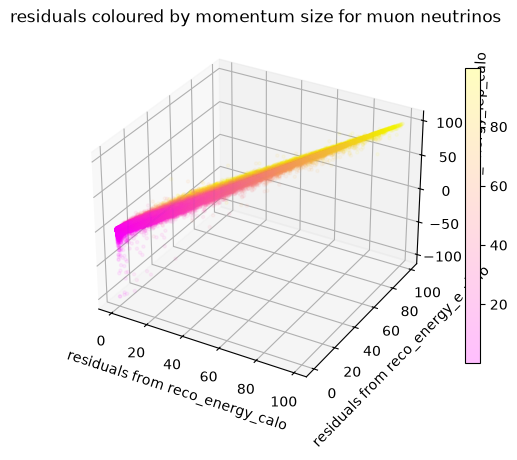

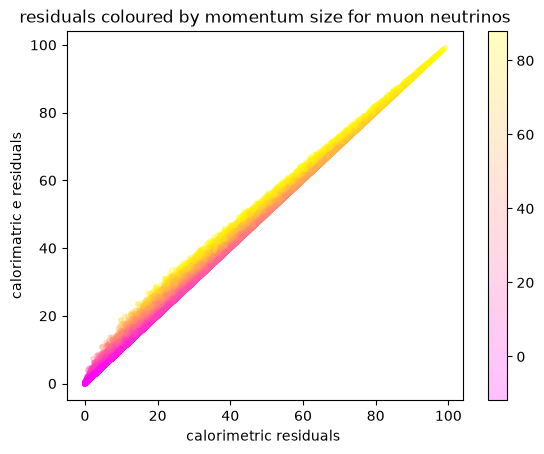

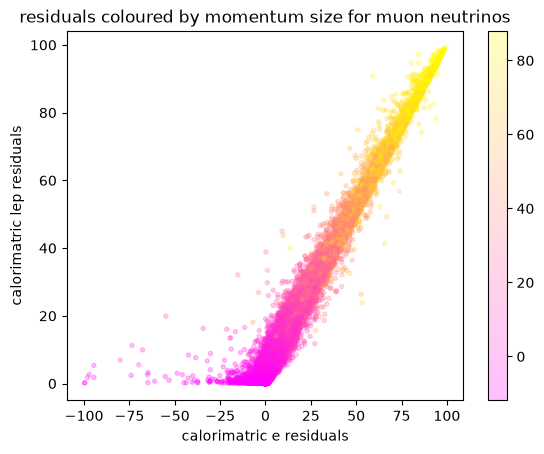

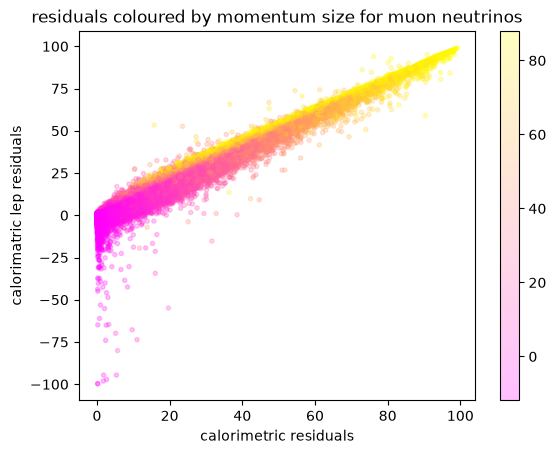

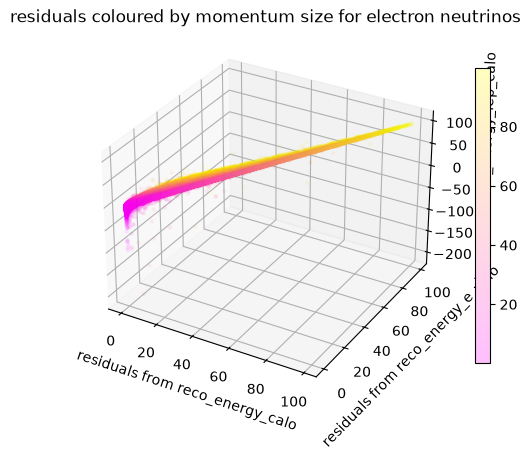

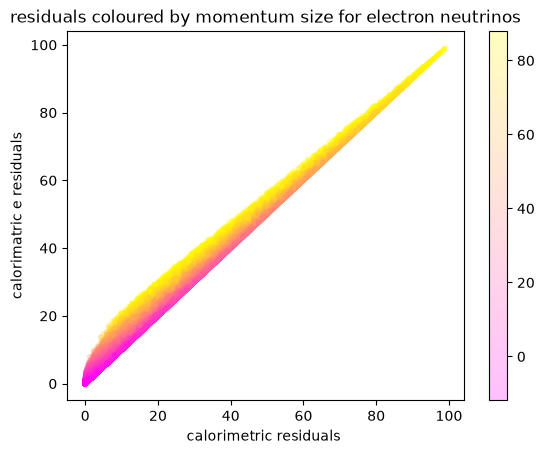

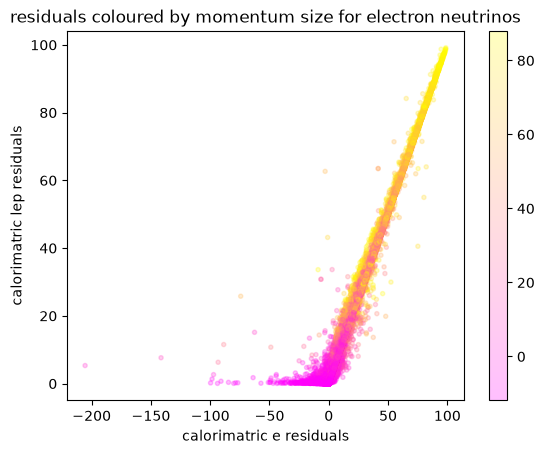

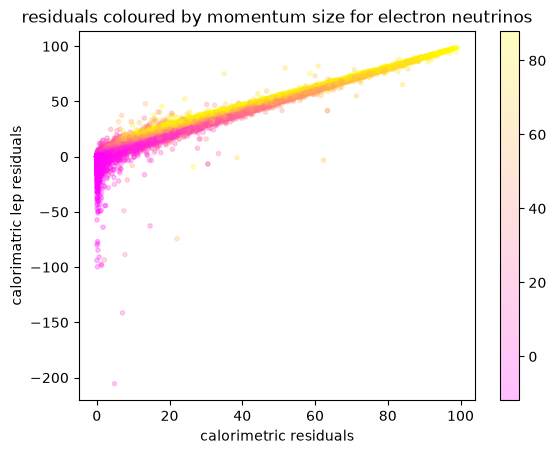

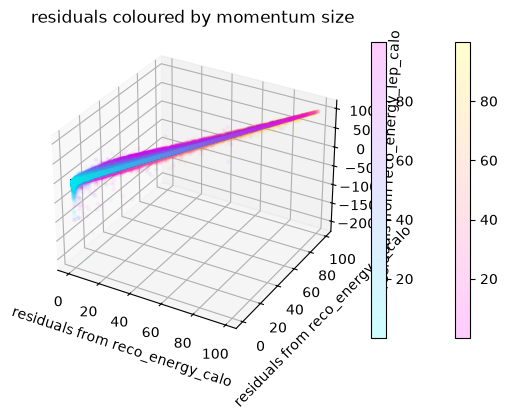

/software/px23572/miniconda/envs/dune-atmo-plot/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


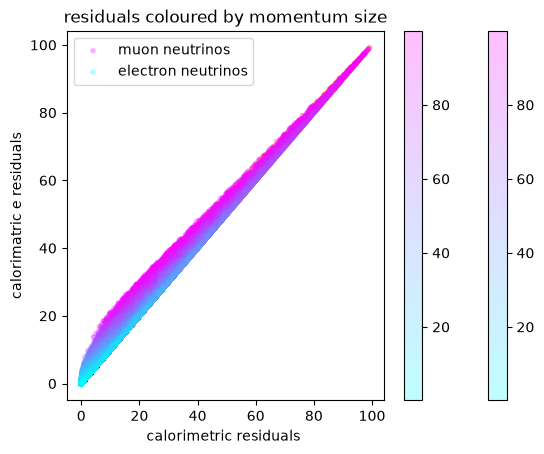

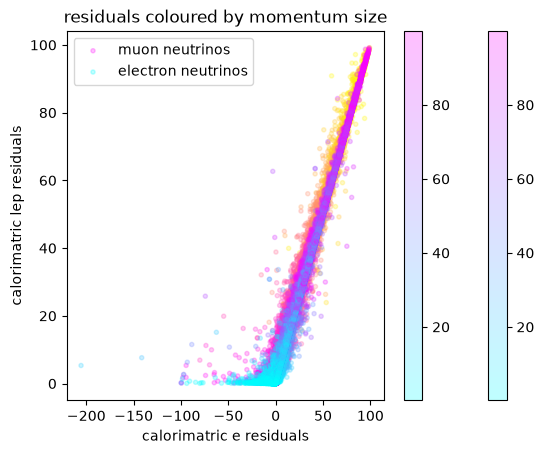

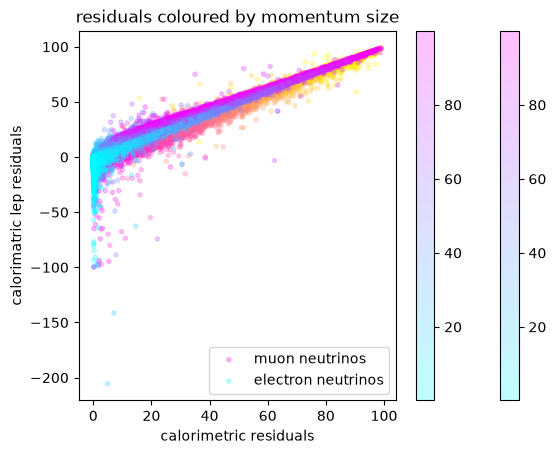

In [ ]:
#calculating the absolute momentum of each neutrino
total_muon_momentum = np.sqrt(muon_neutrinos['x_momentum']**2+muon_neutrinos['y_momentum']**2+muon_neutrinos['z_momentum']**2)
total_electron_momentum = np.sqrt(electron_neutrinos['x_momentum']**2+electron_neutrinos['y_momentum']**2+electron_neutrinos['z_momentum']**2)

#plotting residuals with momentum size colour coded

momentum_3d_plot(muon_residuals_calo,muon_residuals_e_calo,muon_residuals_lep_calo, total_muon_momentum,'residuals from reco_energy_calo','residuals from reco_energy_e_calo','residuals from reco_energy_lep_calo','residuals coloured by momentum size for muon neutrinos')
plot_scatter(muon_residuals_calo,muon_residuals_e_calo, total_muon_momentum,'calorimetric residuals ', 'calorimatric e residuals','residuals coloured by momentum size for muon neutrinos')
plot_scatter(muon_residuals_lep_calo,muon_residuals_e_calo,total_muon_momentum ,'calorimatric e residuals', 'calorimatric lep residuals','residuals coloured by momentum size for muon neutrinos')
plot_scatter(muon_residuals_calo,muon_residuals_lep_calo,total_muon_momentum,'calorimetric residuals', 'calorimatric lep residuals','residuals coloured by momentum size for muon neutrinos')

momentum_3d_plot(electron_residuals_calo,electron_residuals_e_calo,electron_residuals_lep_calo,total_electron_momentum,'residuals from reco_energy_calo','residuals from reco_energy_e_calo','residuals from reco_energy_lep_calo','residuals coloured by momentum size for electron neutrinos')
plot_scatter(electron_residuals_calo,electron_residuals_e_calo, total_electron_momentum,'calorimetric residuals ', 'calorimatric e residuals','residuals coloured by momentum size for electron neutrinos')
plot_scatter(electron_residuals_lep_calo,electron_residuals_e_calo, total_electron_momentum ,'calorimatric e residuals', 'calorimatric lep residuals','residuals coloured by momentum size for electron neutrinos')
plot_scatter(electron_residuals_calo,electron_residuals_lep_calo,total_electron_momentum,'calorimetric residuals', 'calorimatric lep residuals','residuals coloured by momentum size for electron neutrinos')

momentum_3d_double_plot(muon_residuals_calo,muon_residuals_e_calo,muon_residuals_lep_calo,electron_residuals_calo,electron_residuals_e_calo,electron_residuals_lep_calo, total_muon_momentum,total_electron_momentum,'residuals from reco_energy_calo','residuals from reco_energy_e_calo','residuals from reco_energy_lep_calo','muons','electrons','residuals coloured by momentum size')
plot_double_scatter(muon_residuals_calo,muon_residuals_e_calo, electron_residuals_calo,electron_residuals_e_calo, total_muon_momentum, total_electron_momentum,'calorimetric residuals ', 'calorimatric e residuals','muon neutrinos','electron neutrinos','residuals coloured by momentum size')
plot_double_scatter(muon_residuals_lep_calo,muon_residuals_e_calo,electron_residuals_lep_calo,electron_residuals_e_calo,total_muon_momentum ,total_electron_momentum ,'calorimatric e residuals', 'calorimatric lep residuals','muon neutrinos','electron neutrinos','residuals coloured by momentum size')
plot_double_scatter(muon_residuals_calo,muon_residuals_lep_calo,electron_residuals_calo,electron_residuals_lep_calo,total_muon_momentum,total_electron_momentum,'calorimetric residuals', 'calorimatric lep residuals','muon neutrinos','electron neutrinos','residuals coloured by momentum size')
